In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Data Preprocessing**

In [76]:
df = pd.read_csv('/kaggle/input/datasets/sudalairajkumar/indian-startup-funding/startup_funding.csv')

In [77]:
df.head(5)

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


In [78]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Sr No              3044 non-null   int64 
 1   Date dd/mm/yyyy    3044 non-null   object
 2   Startup Name       3044 non-null   object
 3   Industry Vertical  2873 non-null   object
 4   SubVertical        2108 non-null   object
 5   City  Location     2864 non-null   object
 6   Investors Name     3020 non-null   object
 7   InvestmentnType    3040 non-null   object
 8   Amount in USD      2084 non-null   object
 9   Remarks            419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB


In [79]:
df.drop(columns=['Remarks'],inplace=True)

In [80]:
df.rename(columns={
    'Date dd/mm/yyyy':'date',
    'Startup Name':'startup',
    'Industry Vertical':'vertical',
    'SubVertical':'subvertical',
    'City  Location':'city',
    'Investors Name':'investors',
    'InvestmentnType':'round',
    'Amount in USD':'amount'
}
       ,inplace=True  )

In [81]:
df.rename(columns={'Sr No':'serial no'},inplace=True)

In [82]:
df.set_index('serial no',inplace=True)

In [84]:
df['amount'] = df['amount'].fillna('0')

In [85]:
df['amount'] = df['amount'].apply(lambda x:x.replace(',',''))

In [86]:
df['amount'] = df['amount'].apply(lambda x:x.replace('undisclosed','0'))

In [87]:
df['amount'] = df['amount'].apply(lambda x:x.replace('unknown','0'))

In [88]:
df['amount'] = df['amount'].apply(lambda x:x.replace('Undisclosed','0'))

In [89]:
df['amount'] = df['amount'].apply(lambda x:x.replace('Undisclosed','0'))

In [90]:
df = df[df['amount'].str.isdigit()]

In [91]:
df['amount'] = df['amount'].astype(float)

/tmp/ipykernel_57/1060450643.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['amount'] = df['amount'].astype(float)


In [92]:
def to_inr(usd):
    return round((usd * 95.32)/10000000,2)

In [93]:
df['amount'] = df['amount'].apply(to_inr)

/tmp/ipykernel_57/2898200987.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['amount'] = df['amount'].apply(to_inr)


In [97]:
df['date'] = pd.to_datetime(df['date'],format='%d/%m/%Y',errors='coerce')

/tmp/ipykernel_57/565202937.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date'] = pd.to_datetime(df['date'],format='%d/%m/%Y',errors='coerce')


In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3029 entries, 1 to 3044
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3022 non-null   datetime64[ns]
 1   startup      3029 non-null   object        
 2   vertical     2858 non-null   object        
 3   subvertical  2104 non-null   object        
 4   city         2849 non-null   object        
 5   investors    3005 non-null   object        
 6   round        3027 non-null   object        
 7   amount       3029 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 213.0+ KB


In [103]:
df.dropna(subset=['date','startup','vertical','city','investors','round','amount'],inplace=True)

/tmp/ipykernel_57/566745084.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(subset=['date','startup','vertical','city','investors','round','amount'],inplace=True)


In [107]:
df.reset_index(inplace=True)

In [110]:
df.set_index('serial no',inplace=True)

In [111]:
df.to_csv('startup_clean.csv',index=False)

In [ ]:
sorted(set(df['investors'].str.split(',').sum()))

In [4]:
import pandas as pd

In [5]:
df=  pd.read_csv('/kaggle/input/datasets/monirkhan2/clean-data/startup_clean.csv')
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

In [20]:
# recent investments
df[df['investors'].str.contains('Bessemer Venture Partners')].sort_values('date',ascending=False).head(5)

,date,startup,vertical,subvertical,city,investors,round,amount
274,2018-04-10,TravelTriangle,Consumer Internet,Online Travel Marketplace,Gurugram,"Fundamentum, SAIF Partners, Bessemer Venture P...",Private Equity,114.38
296,2018-03-01,PharmEasy,Consumer Internet,Online Pharmacy Store,Mumbai,Bessemer Venture Partners and Orios Venture Pa...,Private Equity,0.00
344,2018-02-12,Wydr,Consumer Internet,B2B Marketplace,Gurugram,"Bessemer Venture Partners, Stellaris Venture P...",Private Equity,0.00
329,2018-02-01,BigBasket,Consumer Internet,Online Grocery & Food Store,Bengaluru,"Alibaba, Helion Venture Partners, Bessemer Ven...",Private Equity,2859.60
428,2017-12-13,DocsApp,Technology,Mobile Application for Doctor Consultation,Bengaluru,Bessemer Venture Partners,Private Equity,68.63


In [21]:
 # biggest investments

temp_df = df[df['investors'].str.contains('Bessemer Venture Partners')].groupby('startup')['amount'].sum().sort_values(ascending=False)

In [22]:
# plotting
import matplotlib.pyplot as plt


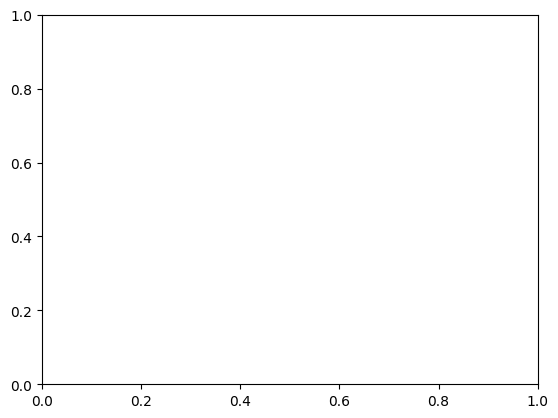

In [23]:
fig,ax = plt.subplots()

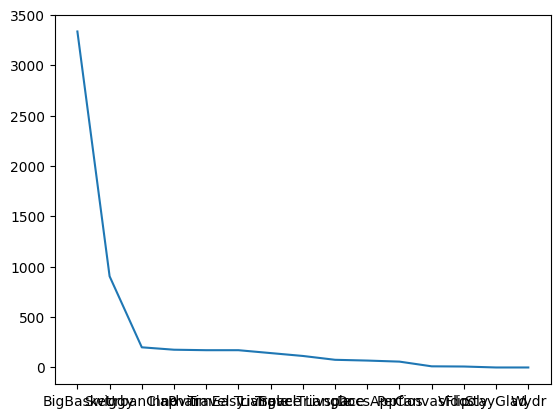

In [24]:
fig,ax = plt.subplots()
ax.plot(temp_df.index,temp_df.values)
plt.show()

In [172]:
plt.show()

<Axes: ylabel='amount'>

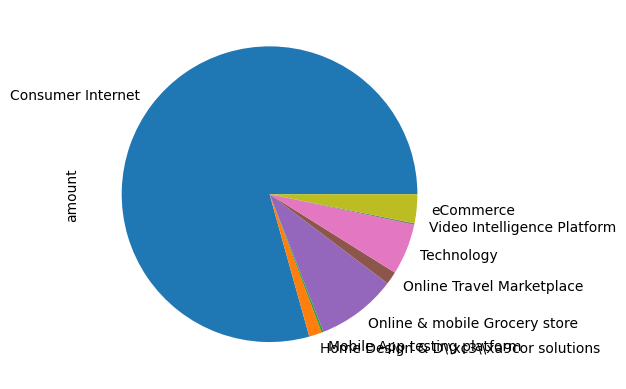

In [185]:
# generally invest in --> sectors
df[df['investors'].str.contains('Bessemer Venture Partners')].groupby('vertical')['amount'].sum().plot(kind='pie')

<Axes: ylabel='amount'>

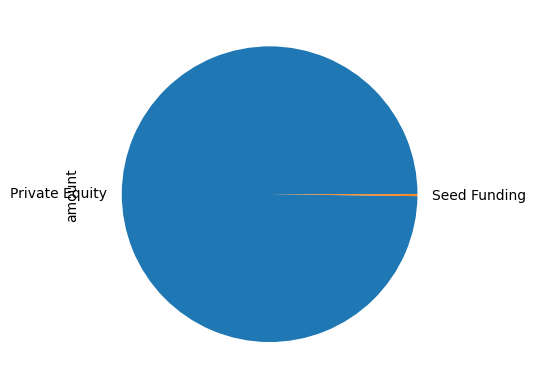

In [25]:
# --> stages
df[df['investors'].str.contains('Bessemer Venture Partners')].groupby('round')['amount'].sum().plot(kind='pie')

In [3]:
df['date'] = pd.to_datetime(df['date'])

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2818 entries, 0 to 2817
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         2818 non-null   datetime64[ns]
 1   startup      2818 non-null   object        
 2   vertical     2818 non-null   object        
 3   subvertical  2077 non-null   object        
 4   city         2818 non-null   object        
 5   investors    2818 non-null   object        
 6   round        2818 non-null   object        
 7   amount       2818 non-null   float64       
 8   year         2818 non-null   int32         
 9   month        2818 non-null   int32         
dtypes: datetime64[ns](1), float64(1), int32(2), object(6)
memory usage: 198.3+ KB


In [4]:
df['year'] = df['date'].dt.year

In [53]:
df.head(3)

,date,startup,vertical,subvertical,city,investors,round,amount,year
0,2020-01-09,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1906.40,2020
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,76.72,2020
2,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,175.00,2020


<Axes: xlabel='year'>

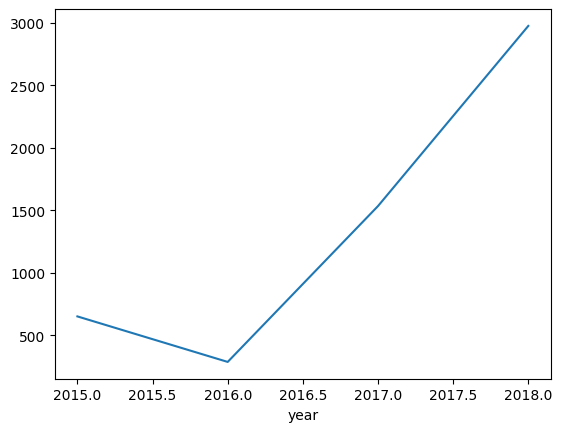

In [8]:
df[df['investors'].str.contains('Bessemer Venture Partners')].groupby('year')['amount'].sum().plot()

In [5]:
round(df['amount'].sum())

342481

In [15]:
df.groupby('startup')['amount'].max().sort_values(ascending=False).head(5)

startup
Rapido Bike Taxi    37174.80
Flipkart            23830.00
Paytm               13344.80
Flipkart.com         6672.40
Udaan                5576.22
Name: amount, dtype: float64

**MoM Chart**

In [5]:
df['month'] = df['date'].dt.month

<Axes: xlabel='year,month'>

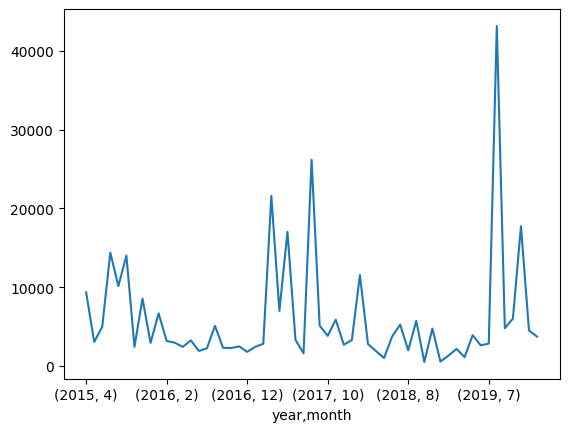

In [21]:
df.groupby(['year','month'])['amount'].sum().plot()

In [10]:
temp_df = df.groupby(['year','month'])['startup'].count().reset_index()
temp_df['x_axis'] = temp_df['year'].astype(str) + '-' + temp_df['month'].astype(str) 

In [8]:
df.sample(3)

,date,startup,vertical,subvertical,city,investors,round,amount,year,month
42,2019-08-01,CarDekho,E-Commerce,Automotive,Gurgaon,SC GG India Mobility Holdings LLC,Series C,190.64,2019,8
2790,2015-04-20,Freshdesk,Online / Mobile Customer Support,NaN,Chennai,"Tiger Global, Google Capital & Accel Partners",Private Equity,476.60,2015,4
2015,2016-01-14,Snapshopr,Consumer Internet,Visual Search & Image Recognition Platform,Bangalore,Amod Malviya,Seed Funding,0.00,2016,1


In [29]:
import matplotlib.pyplot as plt

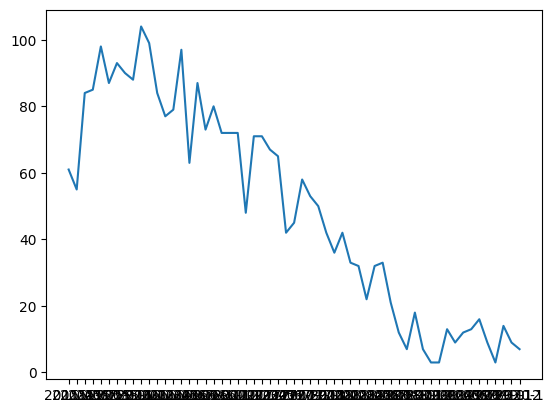

In [12]:
fig,ax = plt.subplots()
ax.plot(temp_df['x_axis'],temp_df['startup'])
plt.show()

In [5]:
df.sample(5)

,date,startup,vertical,subvertical,city,investors,round,amount,year,month
795,2017-05-12,Remit Guru,Consumer Internet,Digital money transfer platform,Mumbai,"Infibeam, CCavenue",Private Equity,4.44,2017,5
62,2019-07-01,Uniphore,Artificial Intelligence,Speech Recognition,Taramani,March Capital Partners,Series C,362.98,2019,7
1559,2016-06-08,Wired Hub,Real Estate,Co-Working Spaces,Jaipur,"Ankit Maheshwari, Anand Singh",Seed Funding,0.00,2016,6
2792,2015-04-22,FindYahan,Hyperlocal services marketplace,NaN,New Delhi,The Phoenix Fund,Private Equity,0.00,2015,4
135,2018-11-25,InCred Finance,Finance,SME Lending,India,"Paragon Partners, Individual Investors",Private Equity,400.34,2018,11


In [10]:
# sector analysis pie --> top sectors(count+sum)
df.groupby('vertical')['amount'].sum().sort_values(ascending=False).head(10)


vertical
Consumer Internet                   59504.85
eCommerce                           47684.14
Transportation                      37333.34
Technology                          21251.14
ECommerce                           17908.71
Finance                             13005.31
FinTech                             11635.82
E-Commerce                           9536.94
Online Marketplace                   6673.76
E-Commerce & M-Commerce platform     6481.76
Name: amount, dtype: float64

In [11]:
df.groupby('vertical')['amount'].count().sort_values(ascending=False).head(10)

vertical
Consumer Internet    927
Technology           476
eCommerce            186
Healthcare            69
ECommerce             61
Finance               58
Logistics             32
E-Commerce            27
Education             23
Food & Beverage       22
Name: amount, dtype: int64

In [2]:
# type of funding


In [13]:
# City wise funding

In [6]:
# top startups --> year wise --> overall
df.sample(4)

,date,startup,vertical,subvertical,city,investors,round,amount,year,month
200,2018-07-25,Black Soil,Finance,Non-Banking Financial Company,Mumbai,"Allcargo Logistics, Navneet Education and Maha...",Private Equity,162.04,2018,7
963,2017-03-30,Klinic App,Consumer Internet,Pathology & Diagnostic Tests Portal,Gurgaon,Om Chaudhry,Seed Funding,0.00,2017,3
481,2017-11-21,Heckyl,Technology,Big Data Analytics Platform,Mumbai,"Notion Capital, IDG Ventures",Private Equity,25.74,2017,11
1994,2016-01-07,MakeMyTrip,Consumer Internet,Online Travel/Hotel Booking platform,Gurgaon,Ctrip.com International Ltd,Private Equity,1715.76,2016,1


In [15]:
# top investors

In [ ]:
# funding heatmap